In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import sys
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score, f1_score

sys.path.append(str(Path.cwd().parent))
from src.main import build_main_model

DATA_DIR = Path.cwd().parent / 'data'
data = pd.read_csv(DATA_DIR / 'train.csv').copy()

X = data.drop(columns=['Survived'])
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

model = build_main_model(n_estimators=500, max_depth=7, max_features=0.75, min_samples_leaf=1)

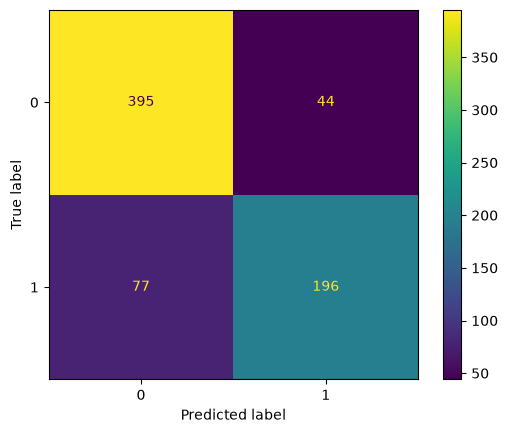

In [ ]:
y_pred = cross_val_predict(model, X_train, y_train, cv=5, n_jobs=-1)
ConfusionMatrixDisplay.from_predictions(y_train, y_pred)
plt.show()

In [19]:
print("-----METRICS-----")
print("Precision: ", precision_score(y_train, y_pred))
print("Recall:", recall_score(y_train, y_pred))
print("F1: ", f1_score(y_train, y_pred))

-----METRICS-----
Precision:  0.8166666666666667
Recall: 0.717948717948718
F1:  0.7641325536062378
